## Consistency of the K-Means Cluster Assignments

This experiment checks whether an evenly spaced action offset task lands in the same cluster when the RL2 agent plays it again.

Every rollout starts from different random initial states of HalfCheetah, so the average hidden state of a task is never exactly the same.

- **Reference:** the average hidden states of the evenly spaced tasks from `kmeans_evenly_spaced.ipynb`. K-Means is fitted on them with the k selected in `kmeans_k_selection.ipynb`, so the clusters are identical to the clusters in the other notebooks.
- **Repetitions:** the same evenly spaced tasks are played `num_repeats` more times, each time with a different seed. The rollout is identical to the one in `kmeans_evenly_spaced.ipynb`, so the only difference to the reference is the random initial states.
- **Assignment:** the average hidden state of every repeated task is assigned to the nearest reference centroid.

**Note:** for HalfCheetah, no k reaches the prediction strength threshold in `kmeans_k_selection.ipynb`, so there is no reproducible cluster structure (k = 1). To compare with the other systems, k = 2 is used here, whose mean prediction strength is just below the threshold. The results for k = 2 are for comparison only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
import sys

from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, os.path.abspath("../.."))
sys.path.insert(0, os.path.abspath(".."))
from analysis_utils import SYSTEMS, CHECKPOINT_DIR, set_seeds, load_model, collect_avg_hidden_states, task_parameters
from kmeans_utils import CLUSTER_COLORS, fit_kmeans, sort_clusters_by_task_parameter

system = SYSTEMS["halfcheetah"]

num_repeats = 20
steps_per_env = 3000

repeat_seeds = 3000 + np.arange(num_repeats)
set_seeds(42)

# Reference run
avg_hidden_states = np.load(
    CHECKPOINT_DIR / "halfcheetah_action_avg_hidden_states.npy"
)
num_envs = len(avg_hidden_states)

env_configs = system.sample_tasks_eval(num_envs=num_envs)
offset_values = task_parameters(system, env_configs)

# k selected with the prediction strength in kmeans_k_selection.ipynb
best_k = int(np.load(
    CHECKPOINT_DIR / "halfcheetah_action_kmeans_k_selection.npz"
)["best_k"])

# No k reaches the threshold for HalfCheetah (k = 1, no reproducible cluster structure).
# k = 2 is used for comparison only, its mean prediction strength is just below the threshold.
selected_k = best_k
if selected_k == 1:
    best_k = 2
comparison_note = ", below threshold, for comparison only" if selected_k == 1 else ""

print(avg_hidden_states.shape)
print(f"Selected k = {selected_k}, used k = {best_k}")

(20, 256)
Selected k = 1, used k = 2


In [2]:
# Create the RL2 model and load the trained weights
model = load_model(system)

### Reference Clusters

K-Means is fitted on the reference hidden states exactly as in `kmeans_repeated_eval.ipynb`. For readability, the clusters are numbered by their mean offset, from the most negative to the most positive.

In [3]:
# Fit K-Means exactly as in kmeans_repeated_eval.ipynb, so the clusters are identical
kmeans = fit_kmeans(avg_hidden_states, best_k)
reference_cluster_assignments = kmeans.labels_

cluster_offset_means, cluster_order, cluster_number = sort_clusters_by_task_parameter(
    reference_cluster_assignments, offset_values, best_k
)

for cluster in cluster_order:
    cluster_offsets = offset_values[reference_cluster_assignments == cluster]

    print(
        f"Cluster {cluster_number[cluster]}: Mean Offset = {cluster_offset_means[cluster]:6.3f} | "
        f"Range = {cluster_offsets.min():6.3f} to {cluster_offsets.max():6.3f}"
    )

Cluster 1: Mean Offset = -0.126 | Range = -0.200 to -0.053
Cluster 2: Mean Offset =  0.084 | Range = -0.032 to  0.200


### Repeated Rollouts

The evenly spaced tasks are played `num_repeats` times for `steps_per_env` steps.

In [4]:
repeat_avg_hidden_states = np.zeros(
    (num_repeats, num_envs, model.feat_extractor.h_dim),
    dtype=avg_hidden_states.dtype
)

envs = system.make_envs(env_configs)

try:
    for repeat, seed in enumerate(repeat_seeds):
        repeat_avg_hidden_states[repeat] = collect_avg_hidden_states(
            model, system, envs, seed=int(seed), steps=steps_per_env
        )
        print(f"Repetition {repeat + 1}/{num_repeats} completed")
finally:
    envs.close()

Repetition 1/20 completed
Repetition 2/20 completed
Repetition 3/20 completed
Repetition 4/20 completed
Repetition 5/20 completed
Repetition 6/20 completed
Repetition 7/20 completed
Repetition 8/20 completed
Repetition 9/20 completed
Repetition 10/20 completed
Repetition 11/20 completed
Repetition 12/20 completed
Repetition 13/20 completed
Repetition 14/20 completed
Repetition 15/20 completed
Repetition 16/20 completed
Repetition 17/20 completed
Repetition 18/20 completed
Repetition 19/20 completed
Repetition 20/20 completed


### Agreement with the Reference Clusters

Every repeated hidden state is assigned to the nearest reference centroid. For each action offset, the table shows its reference cluster, the agreement over all repetitions, and the clusters it was assigned to instead.

In [5]:
# Assign every repeated hidden state to the nearest reference centroid
repeat_cluster_assignments = np.array([
    kmeans.predict(hidden_states) for hidden_states in repeat_avg_hidden_states
])

# True where a task lands in its reference cluster
matches = repeat_cluster_assignments == reference_cluster_assignments[np.newaxis, :]

agreement_per_offset = matches.mean(axis=0)
agreement_per_repeat = matches.mean(axis=1)

print(f"{'Offset':>6} | {'Ref. Cluster':>12} | {'Agreement':>9} | Assigned Instead")

for i, offset in enumerate(offset_values):
    other_clusters = repeat_cluster_assignments[~matches[:, i], i]

    other_text = ", ".join(
        f"Cluster {cluster_number[cluster]} ({np.sum(other_clusters == cluster)}x)"
        for cluster in np.unique(other_clusters)
    ) or "-"

    print(
        f"{offset:6.3f} | {cluster_number[reference_cluster_assignments[i]]:>12} | "
        f"{agreement_per_offset[i]:>9.0%} | {other_text}"
    )

print(f"\nOverall agreement: {matches.mean():.1%}")
print(
    f"Agreement per repetition: mean = {agreement_per_repeat.mean():.1%}, "
    f"std = {agreement_per_repeat.std(ddof=1):.1%}, "
    f"min = {agreement_per_repeat.min():.0%}, max = {agreement_per_repeat.max():.0%}"
)

Offset | Ref. Cluster | Agreement | Assigned Instead
-0.200 |            1 |      100% | -
-0.179 |            1 |      100% | -
-0.158 |            1 |      100% | -
-0.137 |            1 |      100% | -
-0.116 |            1 |      100% | -
-0.095 |            1 |      100% | -
-0.074 |            1 |      100% | -
-0.053 |            1 |      100% | -
-0.032 |            2 |       50% | Cluster 1 (10x)
-0.011 |            2 |      100% | -
 0.011 |            2 |      100% | -
 0.032 |            2 |      100% | -
 0.053 |            2 |      100% | -
 0.074 |            2 |      100% | -
 0.095 |            2 |      100% | -
 0.116 |            2 |      100% | -
 0.137 |            2 |      100% | -
 0.158 |            2 |      100% | -
 0.179 |            2 |      100% | -
 0.200 |            2 |      100% | -

Overall agreement: 97.5%
Agreement per repetition: mean = 97.5%, std = 2.6%, min = 95%, max = 100%


### Visualization

- **Top row:** the cluster of every task in the reference run.
- **Middle rows:** the cluster of every task in each repetition. A cross marks a task that landed in a different cluster than in the reference run.
- **Bottom row:** the agreement per action offset in percent. The darker the cell, the more often the task left its reference cluster.

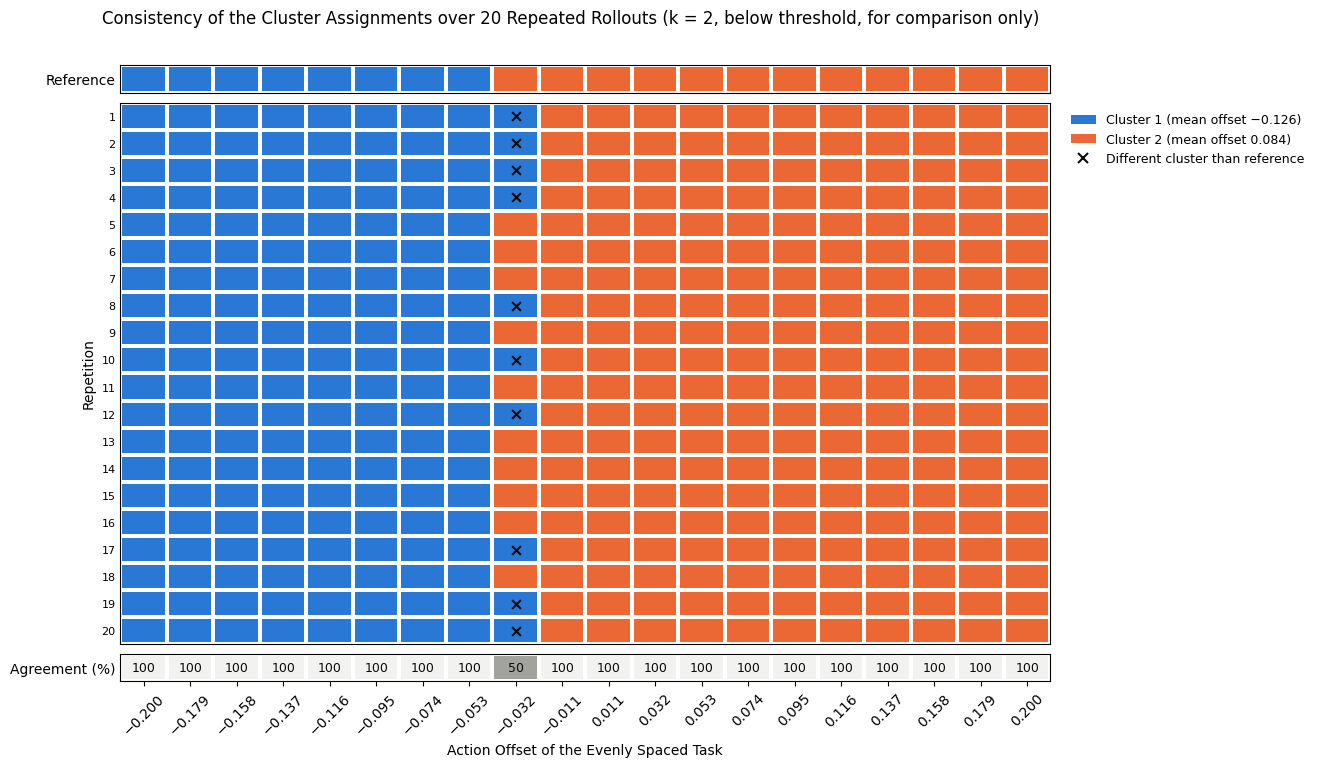

In [6]:
AGREEMENT_HIGH_COLOR = "#f2f2f0"
AGREEMENT_LOW_COLOR = "#52514e"
MISMATCH_COLOR = "#0b0b0b"

assert best_k <= len(CLUSTER_COLORS), "Add more cluster colors for this number of clusters"
cluster_cmap = ListedColormap(CLUSTER_COLORS[:best_k])
agreement_cmap = LinearSegmentedColormap.from_list(
    "agreement", [AGREEMENT_LOW_COLOR, AGREEMENT_HIGH_COLOR]
)

# Cluster numbers (0 = most negative offset) for the color lookup
reference_numbers = cluster_number[reference_cluster_assignments] - 1
repeat_numbers = cluster_number[repeat_cluster_assignments] - 1

x_edges = np.arange(num_envs + 1) - 0.5
x_positions = np.arange(num_envs)

plot_name = "halfcheetah_kmeans_consistency.png"
save_path = os.path.join("diagrams", plot_name)
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Every row has the same height: reference, repetitions, agreement
fig, (ax_ref, ax_rep, ax_agree) = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True,
    gridspec_kw={"height_ratios": [1, num_repeats, 1], "hspace": 0.05}
)

# Cluster of every task: reference run in the top row, repetitions below
for ax, numbers in [(ax_ref, reference_numbers[np.newaxis, :]), (ax_rep, repeat_numbers)]:
    ax.pcolormesh(
        x_edges, np.arange(len(numbers) + 1) - 0.5, numbers,
        cmap=cluster_cmap, vmin=-0.5, vmax=best_k - 0.5,
        edgecolors="white", linewidth=1.5
    )
    ax.invert_yaxis()

    # The offset labels are only shown below the agreement row
    ax.tick_params(axis="x", length=0)

ax_ref.set_yticks([0])
ax_ref.set_yticklabels(["Reference"])

ax_rep.set_yticks(np.arange(num_repeats))
ax_rep.set_yticklabels([str(r + 1) for r in range(num_repeats)], fontsize=8)
ax_rep.set_ylabel("Repetition")

# Cross on every task that left its reference cluster
mismatch_repeats, mismatch_envs = np.nonzero(~matches)
ax_rep.scatter(
    mismatch_envs, mismatch_repeats,
    marker="x", s=40, linewidths=1.5, color=MISMATCH_COLOR, zorder=3
)

# Agreement per action offset as one row below the repetitions
ax_agree.pcolormesh(
    x_edges, [-0.5, 0.5], agreement_per_offset[np.newaxis, :],
    cmap=agreement_cmap, vmin=0, vmax=1,
    edgecolors="white", linewidth=1.5
)

for x, agreement in zip(x_positions, agreement_per_offset):
    ax_agree.text(
        x, 0, f"{agreement * 100:.0f}",
        ha="center", va="center", fontsize=9,
        color="white" if agreement < 0.3 else MISMATCH_COLOR
    )

ax_agree.set_yticks([0])
ax_agree.set_yticklabels(["Agreement (%)"])

# No tick marks next to the row labels
for ax in (ax_ref, ax_rep, ax_agree):
    ax.tick_params(axis="y", length=0)

# Action offsets as x labels
ax_agree.set_xticks(x_positions)
ax_agree.set_xticklabels([f"{w:.3f}".replace("-", "−") for w in offset_values], rotation=45)
ax_agree.set_xlabel("Action Offset of the Evenly Spaced Task")
ax_agree.set_xlim(x_edges[0], x_edges[-1])

# Legend: clusters with their mean offset and crosses
legend_handles = [
    Patch(
        facecolor=CLUSTER_COLORS[number - 1],
        label=f"Cluster {number} (mean offset {cluster_offset_means[cluster]:.3f})".replace("-", "−")
    )
    for cluster, number in sorted(enumerate(cluster_number), key=lambda item: item[1])
]
legend_handles += [
    Line2D([], [], marker="x", linestyle="none", color=MISMATCH_COLOR,
           markersize=7, markeredgewidth=1.5, label="Different cluster than reference"),
]
ax_rep.legend(
    handles=legend_handles, loc="upper left", bbox_to_anchor=(1.01, 1),
    frameon=False, fontsize=9
)

fig.suptitle(
    f"Consistency of the Cluster Assignments over {num_repeats} Repeated Rollouts (k = {best_k}{comparison_note})",
    y=0.95
)
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

In [7]:
# Save the results and corresponding rollout data
np.savez(
    CHECKPOINT_DIR / "halfcheetah_action_kmeans_consistency.npz",
    best_k=best_k,
    selected_k=selected_k,
    offset_values=offset_values,
    repeat_seeds=repeat_seeds,
    reference_cluster_assignments=reference_cluster_assignments,
    repeat_cluster_assignments=repeat_cluster_assignments,
    repeat_avg_hidden_states=repeat_avg_hidden_states,
    agreement_per_offset=agreement_per_offset,
    agreement_per_repeat=agreement_per_repeat
)

print("Consistency results saved.")

Consistency results saved.
